In [57]:
%pip install -q openpyxl matplotlib statsmodels scikit-learn


import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from google.colab import files
from IPython.display import display, Markdown
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

archivo = "https://raw.githubusercontent.com/JavierLartundoUSS/Proyecto-Gesti-n-de-Operaci-n-Grupo-1/main/Proyecto_Filtros_Automotrices.xlsx"
xls = pd.ExcelFile(archivo)
print("Hojas:", xls.sheet_names)
if "Demanda_Historica" not in xls.sheet_names:
    raise ValueError("No existe la hoja Demanda_Historica.")

datos = pd.read_excel(archivo, sheet_name="Demanda_Historica")
display(datos.head())

Note: you may need to restart the kernel to use updated packages.
Hojas: ['Proyecto', 'Demanda_Historica', 'Parametros']


,Mes (AAAA-MM),Demanda (filtros)
0,2020-01,2290
1,2020-02,2830
2,2020-03,3450
3,2020-04,4150
4,2020-05,4790


In [58]:
col_fecha = "Mes (AAAA-MM)"
col_demanda = "Demanda (filtros)"
if col_fecha not in datos.columns or col_demanda not in datos.columns:
    raise ValueError(f"Columnas inesperadas: {list(datos.columns)}")

df = datos[[col_fecha, col_demanda]].copy()
df.columns = ["Mes", "Demanda"]
df["Mes"] = pd.to_datetime(df["Mes"].astype(str), format="%Y-%m", errors="coerce")
df["Demanda"] = pd.to_numeric(df["Demanda"], errors="coerce")
df = df.sort_values("Mes").reset_index(drop=True)

fechas = df["Mes"].dropna().sort_values()
rango = pd.date_range(fechas.min(), fechas.max(), freq="MS")
control = pd.DataFrame({
    "Control": ["Observaciones", "Fechas faltantes", "Demandas faltantes",
                "Fechas duplicadas", "Demandas no positivas", "Meses ausentes"],
    "Resultado": [len(df), int(df["Mes"].isna().sum()), int(df["Demanda"].isna().sum()),
                  int(df["Mes"].duplicated().sum()), int((df["Demanda"].dropna() <= 0).sum()),
                  len(set(rango) - set(fechas))]
})
display(control)
if control["Resultado"].iloc[1:].sum() > 0:
    raise ValueError("La base presenta problemas; revisar antes de modelar.")

y = df.set_index("Mes").asfreq("MS")["Demanda"].astype(float)
print(f"Periodo: {y.index.min():%Y-%m} a {y.index.max():%Y-%m} | Observaciones: {len(y)}")

,Control,Resultado
0,Observaciones,60
1,Fechas faltantes,0
2,Demandas faltantes,0
3,Fechas duplicadas,0
4,Demandas no positivas,0
5,Meses ausentes,0


Periodo: 2020-01 a 2024-12 | Observaciones: 60


,Indicador,Valor
0,Promedio,"7,497.17"
1,Mediana,"7,520.00"
2,Desviación estándar,"2,021.62"
3,Mínimo,"2,290.00"
4,Máximo,"12,070.00"
5,Coeficiente de variación (%),26.97


,Demanda anual,Promedio mensual
Año,,
2020,"57,040.00","4,753.33"
2021,"82,260.00","6,855.00"
2022,"93,630.00","7,802.50"
2023,"106,070.00","8,839.17"
2024,"110,830.00","9,235.83"


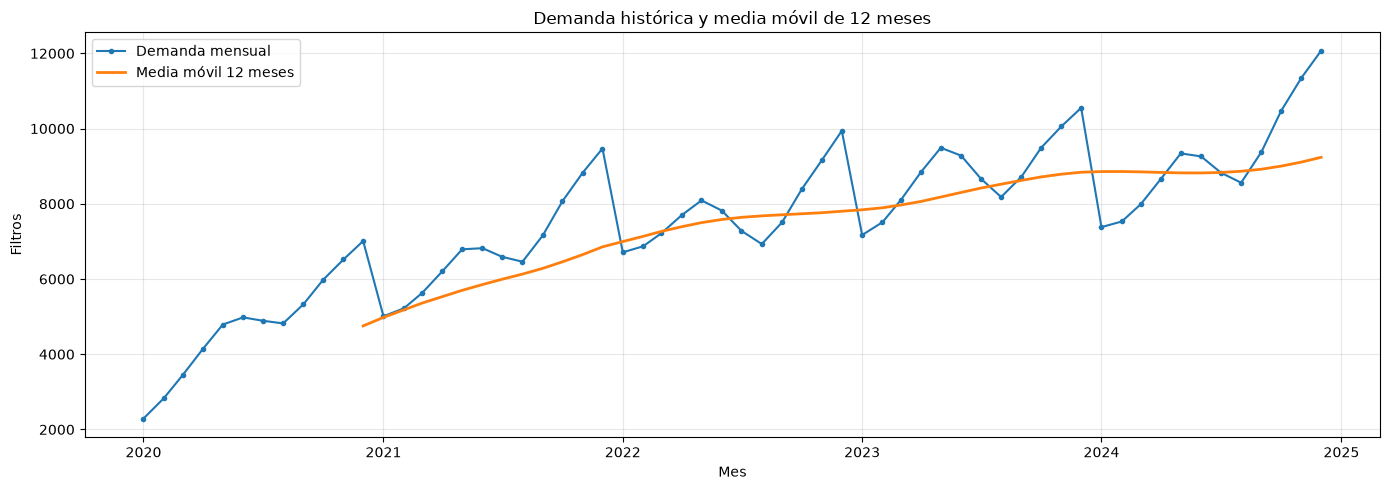

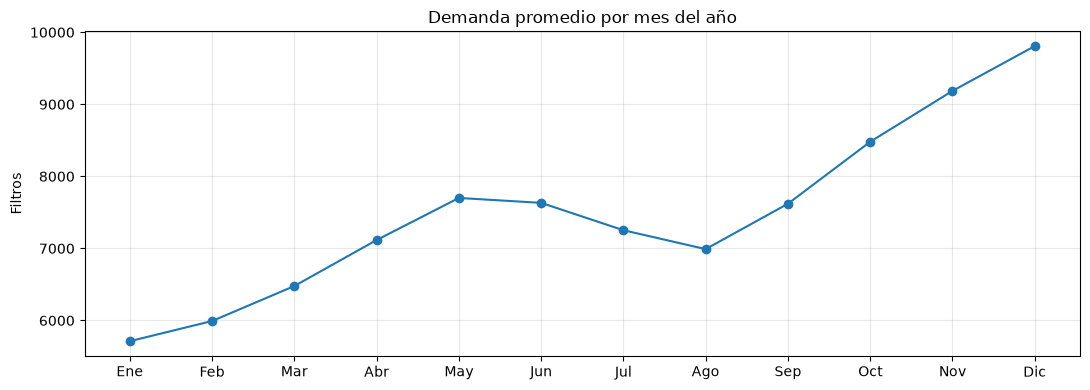

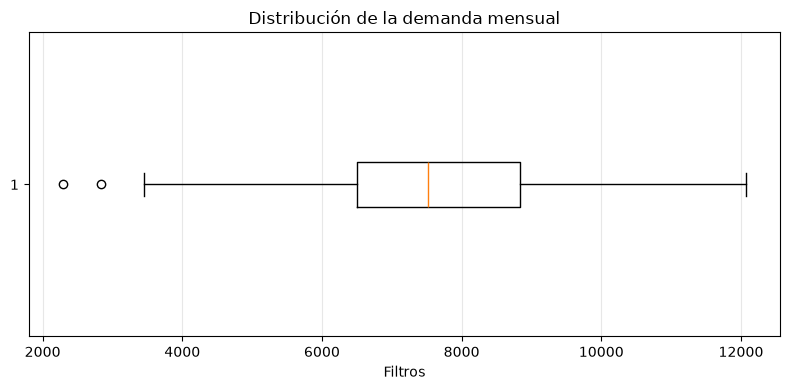

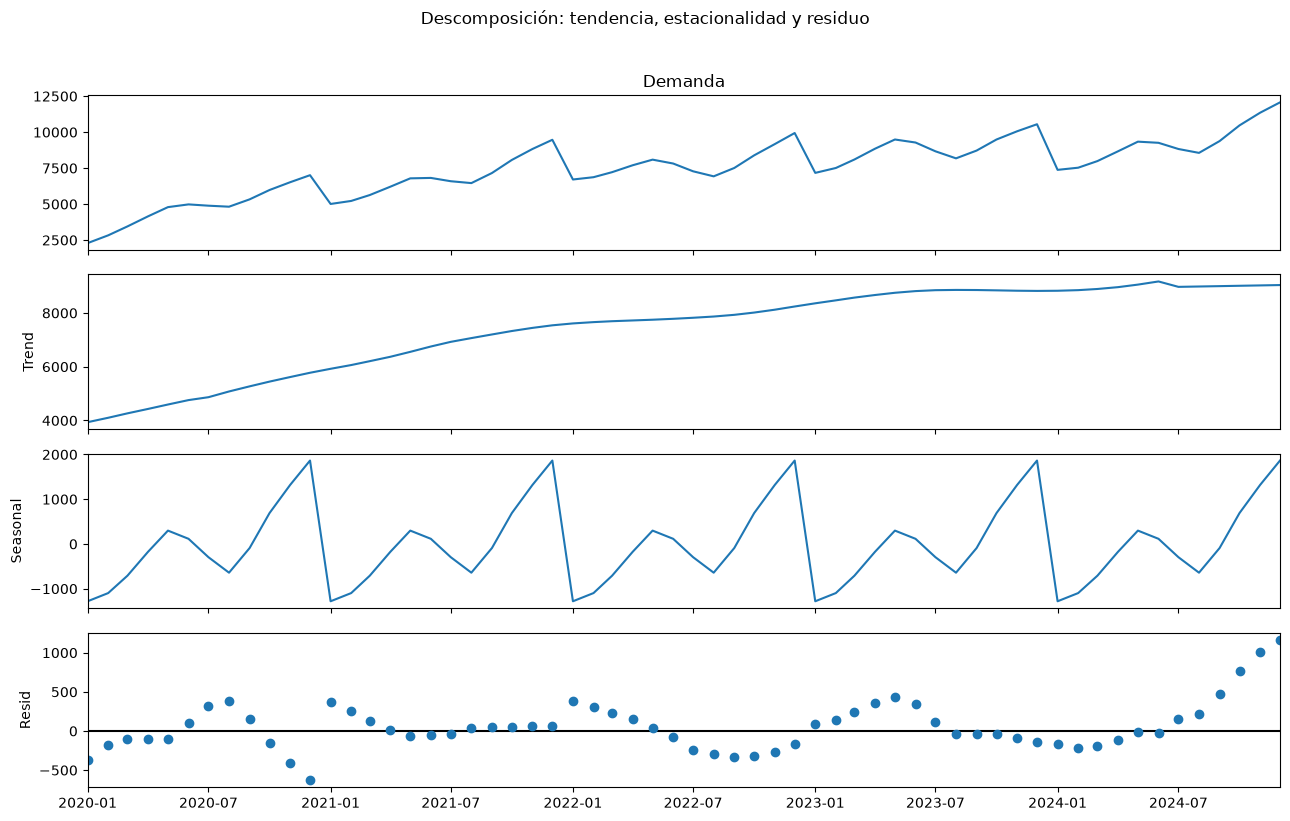

In [59]:
estadisticos = pd.DataFrame({
    "Indicador": ["Promedio", "Mediana", "Desviación estándar", "Mínimo", "Máximo", "Coeficiente de variación (%)"],
    "Valor": [y.mean(), y.median(), y.std(), y.min(), y.max(), y.std()/y.mean()*100]
})
display(estadisticos)

anual = y.resample("YE").agg(["sum", "mean"])
anual.index = anual.index.year
anual.columns = ["Demanda anual", "Promedio mensual"]
anual.index.name = "Año"
display(anual)

plt.figure(figsize=(14,5))
plt.plot(y.index, y, marker="o", markersize=3, label="Demanda mensual")
plt.plot(y.index, y.rolling(12).mean(), linewidth=2, label="Media móvil 12 meses")
plt.title("Demanda histórica y media móvil de 12 meses")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
perfil = y.groupby(y.index.month).mean()
plt.figure(figsize=(11,4))
plt.plot(meses, perfil.values, marker="o")
plt.title("Demanda promedio por mes del año"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
plt.boxplot(y.values, vert=False)
plt.title("Distribución de la demanda mensual"); plt.xlabel("Filtros"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

descomp = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
fig = descomp.plot(); fig.set_size_inches(13,8)
fig.suptitle("Descomposición: tendencia, estacionalidad y residuo", y=1.02)
plt.tight_layout(); plt.show()

In [60]:
corte = pd.Timestamp("2024-01-01")
train = y.loc[y.index < corte]
test = y.loc[y.index >= corte]
if len(train) != 48 or len(test) != 12:
    raise ValueError(f"Se esperaban 48/12 observaciones; se obtuvieron {len(train)}/{len(test)}.")
print(f"Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)} meses)")
print(f"Validación: {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({len(test)} meses)")

Entrenamiento: 2020-01 a 2023-12 (48 meses)
Validación: 2024-01 a 2024-12 (12 meses)


In [61]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {
        "MAE": mean_absolute_error(real, pred),
        "MSE": mean_squared_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "MAPE (%)": np.mean(np.abs((real-pred)/real))*100,
        "Sesgo (real - pronóstico)": np.mean(real-pred)
    }

preds = {}

# Modelo de referencia: repite la demanda del mismo mes del año anterior.
preds["Naive estacional"] = train.iloc[-12:].values

# Mejor alternativa Holt-Winters evaluada.
hw_add = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)
preds["Holt-Winters aditivo"] = hw_add.forecast(12).values

# Primera alternativa SARIMA considerada.
sarima_inicial = SARIMAX(
    train,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 0, 12),
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False)
preds["SARIMA inicial (0,1,1)(0,1,0,12)"] = sarima_inicial.forecast(12).values

# Alternativa SARIMA final recomendada: rendimiento casi idéntico al mínimo
# RMSE, menor MAPE, menor sesgo absoluto y un parámetro menos que (2,0,2).
sarima_final = SARIMAX(
    train,
    order=(2, 0, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False)
preds["SARIMA final (2,0,1)(0,1,1,12)"] = sarima_final.forecast(12).values

# Alternativa de Machine Learning: Random Forest con variables reducidas
# y parámetros seleccionados mediante validación temporal de origen móvil.
LAGS = [1, 12]

def features(hist, fecha):
    return pd.DataFrame([{
        "lag_1": hist.iloc[-1],
        "lag_12": hist.iloc[-12],
        "media_3": hist.iloc[-3:].mean(),
        "mes": fecha.month,
        "t": len(hist)
    }])

def dataset_rf(serie):
    X, objetivo = [], []
    for i in range(max(LAGS), len(serie)):
        X.append(features(serie.iloc[:i], serie.index[i]).iloc[0].to_dict())
        objetivo.append(serie.iloc[i])
    return pd.DataFrame(X), np.asarray(objetivo)

def seleccionar_parametros_rf(serie):
    resultados = []
    inicio_validacion = max(24, max(LAGS) + 6)

    for max_depth in [2, 3, 4, None]:
        for min_samples_leaf in [1, 2, 3]:
            reales, pronosticos = [], []

            for i in range(inicio_validacion, len(serie)):
                historial = serie.iloc[:i]
                X, objetivo = dataset_rf(historial)
                modelo = RandomForestRegressor(
                    n_estimators=500,
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    random_state=42,
                    n_jobs=-1
                ).fit(X, objetivo)

                pronosticos.append(
                    float(modelo.predict(features(historial, serie.index[i]))[0])
                )
                reales.append(float(serie.iloc[i]))

            resultados.append({
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "RMSE temporal": np.sqrt(mean_squared_error(reales, pronosticos))
            })

    tabla = pd.DataFrame(resultados).sort_values("RMSE temporal").reset_index(drop=True)
    mejor = tabla.iloc[0]
    return {
        "max_depth": mejor["max_depth"],
        "min_samples_leaf": int(mejor["min_samples_leaf"])
    }, tabla

rf_params, validacion_rf = seleccionar_parametros_rf(train)
display(Markdown(
    f"**Random Forest seleccionado:** max_depth={rf_params['max_depth']}, "
    f"min_samples_leaf={rf_params['min_samples_leaf']}"
))
display(validacion_rf.head().round(2))

Xrf, yrf = dataset_rf(train)
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=rf_params["max_depth"],
    min_samples_leaf=rf_params["min_samples_leaf"],
    random_state=42,
    n_jobs=-1
).fit(Xrf, yrf)

historial_rf = train.copy()
pred_rf = []
for fecha in test.index:
    valor = float(rf.predict(features(historial_rf, fecha))[0])
    pred_rf.append(valor)
    historial_rf.loc[fecha] = valor

preds["Random Forest"] = np.asarray(pred_rf)

# Alternativas consideradas para el informe, pero no ejecutadas:
# - Holt-Winters amortiguado.
# - Holt-Winters con tendencia multiplicativa.
# - SARIMA (1,1,1) y SARIMA (2,1,2), entre otras configuraciones.
# - SARIMA (2,0,2)(0,1,1,12), que obtuvo el menor RMSE, pero utiliza
#   un parámetro adicional y tuvo resultados prácticamente iguales al modelo final.

tabla_metricas = pd.DataFrame([
    {"Modelo": nombre, **metricas(test.values, pred)}
    for nombre, pred in preds.items()
]).sort_values("RMSE").reset_index(drop=True)
display(tabla_metricas.round(2))


KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(test.index, test.values, marker="o", linewidth=3, label="Demanda real")
for nombre, pred in preds.items():
    plt.plot(test.index, pred, marker=".", linestyle="--", label=nombre)
plt.title("Validación temporal: real vs pronósticos (2024)")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(ncol=2); plt.tight_layout(); plt.show()

orden = tabla_metricas.sort_values("RMSE")
plt.figure(figsize=(10,5))
plt.barh(orden["Modelo"], orden["RMSE"])
plt.title("Comparación de modelos según RMSE"); plt.xlabel("RMSE (filtros)")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

mejor_modelo = tabla_metricas.iloc[0]["Modelo"]

errores = pd.DataFrame({"Demanda real": test})
for nombre, pred in preds.items():
    if nombre != mejor_modelo:
        errores[nombre] = pred

errores[mejor_modelo] = preds[mejor_modelo]
errores["Diferencia real - modelo electo"] = (
    errores["Demanda real"] - errores[mejor_modelo]
)
display(errores.round(2))

residuos = errores["Diferencia real - modelo electo"].to_numpy()
plt.figure(figsize=(12,4))
plt.axhline(0, linestyle="--")
plt.plot(test.index, residuos, marker="o")
plt.title(f"Residuos de validación: {mejor_modelo}")
plt.ylabel("Real - pronóstico"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
modelo_seleccionado = mejor_modelo
display(Markdown(f"### Modelo con menor RMSE: **{modelo_seleccionado}**"))
display(tabla_metricas[tabla_metricas["Modelo"] == modelo_seleccionado].round(2))

### Modelo con menor RMSE: **SARIMA final (2,0,1)(0,1,1,12)**

,Modelo,MAE,MSE,RMSE,MAPE (%),Sesgo (real - pronóstico)
0,"SARIMA final (2,0,1)(0,1,1,12)",438.37,"252,824.83",502.82,4.62,-86.45


In [ ]:
def pronosticar(nombre, serie, h=12):
    if nombre == "Naive estacional":
        return np.tile(serie.iloc[-12:].values, int(np.ceil(h/12)))[:h]

    if nombre == "Holt-Winters aditivo":
        modelo = ExponentialSmoothing(
            serie,
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated"
        ).fit(optimized=True)
        return modelo.forecast(h).values

    if nombre == "SARIMA inicial (0,1,1)(0,1,0,12)":
        modelo = SARIMAX(
            serie,
            order=(0, 1, 1),
            seasonal_order=(0, 1, 0, 12),
            enforce_stationarity=True,
            enforce_invertibility=True
        ).fit(disp=False)
        return modelo.forecast(h).values

    if nombre == "SARIMA final (2,0,1)(0,1,1,12)":
        modelo = SARIMAX(
            serie,
            order=(2, 0, 1),
            seasonal_order=(0, 1, 1, 12),
            enforce_stationarity=True,
            enforce_invertibility=True
        ).fit(disp=False)
        return modelo.forecast(h).values

    if nombre == "Random Forest":
        parametros, _ = seleccionar_parametros_rf(serie)
        X, objetivo = dataset_rf(serie)
        modelo = RandomForestRegressor(
            n_estimators=500,
            max_depth=parametros["max_depth"],
            min_samples_leaf=parametros["min_samples_leaf"],
            random_state=42,
            n_jobs=-1
        ).fit(X, objetivo)

        historial = serie.copy()
        fechas = pd.date_range(
            serie.index[-1] + pd.offsets.MonthBegin(1),
            periods=h,
            freq="MS"
        )
        salida = []
        for fecha in fechas:
            valor = float(modelo.predict(features(historial, fecha))[0])
            salida.append(valor)
            historial.loc[fecha] = valor
        return np.asarray(salida)

    raise ValueError(f"Modelo no reconocido: {nombre}")

fechas_futuras = pd.date_range(
    y.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)
valores = pronosticar(modelo_seleccionado, y, 12)
q025, q975 = np.quantile(residuos, [0.025, 0.975])

pronostico = pd.DataFrame({
    "Mes": fechas_futuras.strftime("%Y-%m"),
    "Pronostico": valores,
    "Limite_inferior_aprox": np.maximum(0, valores + q025),
    "Limite_superior_aprox": np.maximum(0, valores + q975)
})
display(pronostico.round(0))
print(f"Total del horizonte: {pronostico['Pronostico'].sum():,.0f} filtros")
print(f"Modelo utilizado: {modelo_seleccionado}")
print(f"Residuos para banda empírica: {len(residuos)}")

fechas_plot = pd.to_datetime(pronostico["Mes"])
plt.figure(figsize=(14,6))
plt.plot(y.index, y.values, label="Demanda histórica", linewidth=2)
plt.plot(fechas_plot, valores, marker="o", label="Pronóstico 12 meses")
plt.fill_between(
    fechas_plot,
    pronostico["Limite_inferior_aprox"],
    pronostico["Limite_superior_aprox"],
    alpha=.2,
    label="Banda empírica"
)
plt.axvline(y.index[-1], linestyle="--", label="Inicio del horizonte")
plt.title("Demanda histórica y pronóstico de 12 meses")
plt.xlabel("Mes")
plt.ylabel("Filtros")
plt.grid(alpha=.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
plt.bar(fechas_plot.dt.strftime("%b-%Y"), valores)
plt.title("Pronóstico mensual")
plt.ylabel("Filtros")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


In [ ]:
fila_sel = tabla_metricas.loc[tabla_metricas["Modelo"] == modelo_seleccionado].iloc[0]
resumen = pd.DataFrame({
    "Indicador": ["Observaciones", "Inicio histórico", "Fin histórico", "Modelo seleccionado",
                  "MAE", "RMSE", "MAPE (%)", "Sesgo", "Total pronosticado"],
    "Resultado": [len(y), y.index.min().strftime("%Y-%m"), y.index.max().strftime("%Y-%m"),
                  modelo_seleccionado, fila_sel["MAE"], fila_sel["RMSE"], fila_sel["MAPE (%)"],
                  fila_sel["Sesgo (real - pronóstico)"], pronostico["Pronostico"].sum()]
})
display(resumen)

control.to_csv("control_calidad_sprint1.csv", index=False, encoding="utf-8-sig")
tabla_metricas.to_csv("metricas_validacion_sprint1.csv", index=False, encoding="utf-8-sig")
errores.to_csv("comparacion_validacion_2024.csv", encoding="utf-8-sig")
pronostico.to_csv("pronostico_12_meses_sprint1.csv", index=False, encoding="utf-8-sig")
resumen.to_csv("resumen_ejecutivo_sprint1.csv", index=False, encoding="utf-8-sig")

for nombre in ["control_calidad_sprint1.csv", "metricas_validacion_sprint1.csv",
               "comparacion_validacion_2024.csv", "pronostico_12_meses_sprint1.csv",
               "resumen_ejecutivo_sprint1.csv"]:
    if os.path.exists(nombre):
        print(f"Archivo generado: {nombre}")
        

,Indicador,Resultado
0,Observaciones,60
1,Inicio histórico,2020-01
2,Fin histórico,2024-12
3,Modelo seleccionado,"SARIMA final (2,0,1)(0,1,1,12)"
4,MAE,438.37
5,RMSE,502.82
6,MAPE (%),4.62
7,Sesgo,-86.45
8,Total pronosticado,"115,543.74"


Archivo generado: control_calidad_sprint1.csv
Archivo generado: metricas_validacion_sprint1.csv
Archivo generado: comparacion_validacion_2024.csv
Archivo generado: pronostico_12_meses_sprint1.csv
Archivo generado: resumen_ejecutivo_sprint1.csv
